# Perbandingan Metode: K-Means vs X-Means

**Tujuan**: Menentukan metode clustering mana yang lebih cocok untuk dataset karyawan (`Report.csv`).

| Aspek | K-Means | X-Means |
|---|---|---|
| Jumlah cluster | Harus ditentukan manual (K) | Otomatis (cari K terbaik via BIC) |
| Kriteria split | Minimasi SSE/Inertia | Bayesian Information Criterion (BIC) |
| Kecepatan | Sangat cepat | Lebih lambat (iteratif) |
| Fleksibilitas | Perlu evaluasi K secara terpisah | Sekaligus menemukan K optimal |

**Pipeline**:
1. Load & preprocessing data (sama seperti notebook utama)
2. Jalankan K-Means dengan K terbaik (majority voting)
3. Jalankan X-Means (K otomatis via BIC)
4. Bandingkan hasil: Silhouette, DBI, CH, distribusi cluster, waktu komputasi
5. Kesimpulan & rekomendasi

## 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
import time
from collections import Counter
warnings.filterwarnings('ignore')

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
)

# X-Means dari pyclustering
# Center awal akan dibuat manual via sklearn KMeans (lihat Cell 5)
from pyclustering.cluster.xmeans import xmeans, splitting_type

print('✅ Semua library berhasil diimport')
print(f'   NumPy  : {np.__version__}')
print(f'   sklearn: tersedia')
print(f'   pyclustering xmeans: siap (inisialisasi center via sklearn)')

✅ Semua library berhasil diimport
   NumPy  : 2.4.4
   sklearn: tersedia
   pyclustering xmeans: siap (inisialisasi center via sklearn)


## 2. Load & Preprocessing Data

> Cell ini identik dengan notebook utama — direplikasi agar notebook ini berdiri sendiri.

In [2]:
# ── Load ─────────────────────────────────────────────────────
df = pd.read_csv('Report.csv')
print(f'Raw data: {df.shape[0]:,} baris, {df.shape[1]} kolom')

KOLOM_WAJIB = [
    'Username', 'Tanggal Visit',
    'Area', 'Nama Karyawan', 'Region', 'Role',
    'Nama Store',
    'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available',
]

kolom_ada    = [c for c in KOLOM_WAJIB if c in df.columns]
kolom_hilang = [c for c in KOLOM_WAJIB if c not in df.columns]
if kolom_hilang:
    print(f'Kolom tidak ditemukan (akan diisi "-"): {kolom_hilang}')
    for c in kolom_hilang:
        df[c] = '-'

df = df[KOLOM_WAJIB].copy()

# ── Tipe data ─────────────────────────────────────────────────
df['Tanggal Visit'] = pd.to_datetime(df['Tanggal Visit'], errors='coerce')
df['Facing']        = pd.to_numeric(df['Facing'], errors='coerce').fillna(0).clip(lower=0)
df['Is FIFO/FEFO']           = df['Is FIFO/FEFO'].astype(str).str.upper().str.strip()
df['Is Price Tag Available'] = df['Is Price Tag Available'].astype(str).str.upper().str.strip()

# ── Filter Username ───────────────────────────────────────────
df = df[df['Username'].astype(str).str.match(r'^ID-', na=False)].copy()

# ── Filter sentinel FIFO/FEFO = -1 ───────────────────────────
df = df[df['Is FIFO/FEFO'] != '-1'].copy()

# ── Normalisasi KPI → YA/TIDAK ───────────────────────────────
MAP_YA = {'YA', '1', 'TRUE', 'YES'}
def normalize_kpi(val):
    v = str(val).upper().strip()
    return 'YA' if v in MAP_YA else 'TIDAK'

df['Is FIFO/FEFO']           = df['Is FIFO/FEFO'].apply(normalize_kpi)
df['Is Price Tag Available'] = df['Is Price Tag Available'].apply(normalize_kpi)

# ── Normalisasi Facing (clip p05-p95 → 0-1) ──────────────────
if df['Facing'].max() > 1.0:
    p05 = df['Facing'].quantile(0.05)
    p95 = df['Facing'].quantile(0.95)
    df['Facing'] = (df['Facing'].clip(lower=p05, upper=p95) - p05) / (p95 - p05)
    print(f'Facing dinormalisasi ke 0-1  (clip [{p05:.2f}, {p95:.2f}])')

print(f'\n✅ Data siap: {len(df):,} baris kunjungan valid')

Raw data: 643,310 baris, 32 kolom
Facing dinormalisasi ke 0-1  (clip [0.00, 2.00])

✅ Data siap: 643,048 baris kunjungan valid


## 3. Groupby per Karyawan & Feature Selection

In [3]:
# ── Groupby per Username ──────────────────────────────────────
df_grouped = (
    df.groupby('Username')
    .agg(
        Facing      = ('Facing',                 'mean'),
        Is_FIFO     = ('Is FIFO/FEFO',           lambda x: (x == 'YA').mean()),
        Is_PriceTag = ('Is Price Tag Available', lambda x: (x == 'YA').mean()),
        visit_count = ('Tanggal Visit',          'count'),
    )
    .rename(columns={'Is_FIFO': 'Is FIFO/FEFO', 'Is_PriceTag': 'Is Price Tag Available'})
    .reset_index()
    .fillna(0)
)

print(f'Total karyawan untuk clustering: {len(df_grouped)}')

# ── Feature selection: buang fitur dengan std < 0.001 atau >95% nol ──
feature_cols_all = ['visit_count', 'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available']
ACTIVE_FEATURES  = []
excluded         = []

print('\n=== Seleksi Fitur ===')
for col in feature_cols_all:
    std      = df_grouped[col].std()
    pct_zero = (df_grouped[col] == 0).mean() * 100
    if std < 0.001:
        status = 'EXCLUDE (tidak bervariasi)'
        excluded.append(col)
    elif col != 'visit_count' and pct_zero > 95:
        status = f'EXCLUDE ({pct_zero:.0f}% nol)'
        excluded.append(col)
    else:
        status = 'OK'
        ACTIVE_FEATURES.append(col)
    print(f'  {col:<30}: std={std:.4f}  %nol={pct_zero:.1f}%  → {status}')

print(f'\nFitur aktif : {ACTIVE_FEATURES}')
if excluded:
    print(f'Di-exclude  : {excluded}')

# ── Scaling ───────────────────────────────────────────────────
X = df_grouped[ACTIVE_FEATURES].values
scaler   = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
print(f'\nShape X_scaled: {X_scaled.shape}')

Total karyawan untuk clustering: 80

=== Seleksi Fitur ===
  visit_count                   : std=3394.4304  %nol=0.0%  → OK
  Facing                        : std=0.0742  %nol=0.0%  → OK
  Is FIFO/FEFO                  : std=0.1522  %nol=0.0%  → OK
  Is Price Tag Available        : std=0.1557  %nol=0.0%  → OK

Fitur aktif : ['visit_count', 'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available']

Shape X_scaled: (80, 4)


## 4. K-Means — Pemilihan K Optimal (Majority Voting)

In [4]:
K_MAX   = min(10, len(df_grouped) - 1)
K_RANGE = range(2, K_MAX + 1)

inertia_list = []
sil_list     = []
dbi_list     = []
ch_list      = []

t0 = time.time()
for k in K_RANGE:
    km     = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia_list.append(km.inertia_)
    sil_list.append(silhouette_score(X_scaled, labels))
    dbi_list.append(davies_bouldin_score(X_scaled, labels))
    ch_list.append(calinski_harabasz_score(X_scaled, labels))

km_selection_time = time.time() - t0

best_sil_k = list(K_RANGE)[sil_list.index(max(sil_list))]
best_dbi_k = list(K_RANGE)[dbi_list.index(min(dbi_list))]
best_ch_k  = list(K_RANGE)[ch_list.index(max(ch_list))]

votes      = [best_sil_k, best_dbi_k, best_ch_k]
vote_count = Counter(votes)
BEST_K_KM  = vote_count.most_common(1)[0][0]
if vote_count.most_common(1)[0][1] == 1:
    BEST_K_KM = best_sil_k  # tie-break → Silhouette

print(f'Silhouette terbaik       : k={best_sil_k}')
print(f'Davies-Bouldin terbaik   : k={best_dbi_k}')
print(f'Calinski-Harabasz terbaik: k={best_ch_k}')
print(f'✅ K-Means K optimal     : k={BEST_K_KM}')
print(f'   Waktu seleksi K       : {km_selection_time:.2f} detik')

Silhouette terbaik       : k=2
Davies-Bouldin terbaik   : k=2
Calinski-Harabasz terbaik: k=2
✅ K-Means K optimal     : k=2
   Waktu seleksi K       : 2.10 detik


In [5]:
# ── Training model final K-Means ─────────────────────────────
t0 = time.time()
kmeans_final = KMeans(n_clusters=BEST_K_KM, random_state=42, n_init=10)
km_labels    = kmeans_final.fit_predict(X_scaled)
km_fit_time  = time.time() - t0

km_sil = silhouette_score(X_scaled, km_labels)
km_dbi = davies_bouldin_score(X_scaled, km_labels)
km_ch  = calinski_harabasz_score(X_scaled, km_labels)
km_sse = kmeans_final.inertia_

print(f'K-Means Final (k={BEST_K_KM})')
print(f'  Silhouette Score     : {km_sil:.4f}')
print(f'  Davies-Bouldin Index : {km_dbi:.4f}')
print(f'  Calinski-Harabasz    : {km_ch:.2f}')
print(f'  Inertia (SSE)        : {km_sse:.2f}')
print(f'  Waktu fit            : {km_fit_time:.4f} detik')
print(f'  Distribusi cluster   : {Counter(km_labels.tolist())}')

K-Means Final (k=2)
  Silhouette Score     : 0.6179
  Davies-Bouldin Index : 0.5409
  Calinski-Harabasz    : 89.61
  Inertia (SSE)        : 5.24
  Waktu fit            : 0.0247 detik
  Distribusi cluster   : Counter({0: 70, 1: 10})


## 5. X-Means — K Otomatis via BIC

X-Means adalah ekstensi K-Means yang secara **otomatis** mencari jumlah cluster optimal.  
Algoritma ini memulai dari K kecil, lalu **memisahkan** setiap cluster jika pemisahan tersebut meningkatkan **Bayesian Information Criterion (BIC)**.  

**BIC** = log-likelihood − (½ × jumlah parameter × ln(n))  
Semakin tinggi BIC, semakin baik model tanpa overfitting.

In [6]:
# ── X-Means ──────────────────────────────────────────────────
# dengan NumPy >= 1.24 (AttributeError: numpy.warnings dihapus).
# Solusi: gunakan sklearn KMeans untuk menghasilkan pusat awal K=2,
# lalu operkan hasilnya sebagai list Python ke xmeans pyclustering.

K_INIT_XM = 2
K_MAX_XM  = min(20, len(df_grouped) // 2)  # batas atas pencarian

# Inisialisasi center awal menggunakan sklearn (bukan pyclustering initializer)
_km_init = KMeans(n_clusters=K_INIT_XM, init='k-means++',
                  n_init=1, random_state=42, max_iter=1)
_km_init.fit(X_scaled)
init_centers = _km_init.cluster_centers_.tolist()  # list of list — kompatibel pyclustering

print(f'Pusat awal K={K_INIT_XM} dari sklearn k-means++:')
for i, c in enumerate(init_centers):
    print(f'  Center {i}: {[round(v,4) for v in c]}')

xm_instance = xmeans(
    data            = X_scaled.tolist(),
    initial_centers = init_centers,
    kmax            = K_MAX_XM,
    splitting_type  = splitting_type.BAYESIAN_INFORMATION_CRITERION,
    random_state    = 42,
)

t0 = time.time()
xm_instance.process()
xm_fit_time = time.time() - t0

# ── Ambil hasil ───────────────────────────────────────────────
xm_clusters = xm_instance.get_clusters()   # list of list (index per cluster)
xm_centers  = xm_instance.get_centers()    # list of center coords
BEST_K_XM   = len(xm_clusters)

# Konversi ke label array (sama format dengan K-Means)
xm_labels = np.zeros(len(X_scaled), dtype=int)
for cid, members in enumerate(xm_clusters):
    for idx in members:
        xm_labels[idx] = cid

# ── Evaluasi X-Means ─────────────────────────────────────────
xm_sil = silhouette_score(X_scaled, xm_labels)
xm_dbi = davies_bouldin_score(X_scaled, xm_labels)
xm_ch  = calinski_harabasz_score(X_scaled, xm_labels)
# SSE manual (karena X-Means tidak expose inertia)
centers_arr = np.array(xm_centers)
xm_sse = sum(
    np.sum((X_scaled[np.array(members)] - centers_arr[cid]) ** 2)
    for cid, members in enumerate(xm_clusters)
)

print(f'\nX-Means menemukan K = {BEST_K_XM} cluster secara otomatis')
print(f'  Silhouette Score     : {xm_sil:.4f}')
print(f'  Davies-Bouldin Index : {xm_dbi:.4f}')
print(f'  Calinski-Harabasz    : {xm_ch:.2f}')
print(f'  SSE (manual)         : {xm_sse:.2f}')
print(f'  Waktu fit            : {xm_fit_time:.4f} detik')
print(f'  Distribusi cluster   : {dict(sorted(Counter(xm_labels.tolist()).items()))}')

Pusat awal K=2 dari sklearn k-means++:
  Center 0: [0.3979, 0.2907, 0.3526, 0.428]
  Center 1: [0.196, 0.6565, 0.8894, 0.9028]

X-Means menemukan K = 2 cluster secara otomatis
  Silhouette Score     : 0.6179
  Davies-Bouldin Index : 0.5409
  Calinski-Harabasz    : 89.61
  SSE (manual)         : 5.24
  Waktu fit            : 0.0024 detik
  Distribusi cluster   : {0: 70, 1: 10}


## 6. Tabel Perbandingan Metrik

In [7]:
# ── Tabel perbandingan ────────────────────────────────────────
comparison = pd.DataFrame({
    'Metrik'              : ['K (cluster)', 'Silhouette Score ↑',
                             'Davies-Bouldin ↓', 'Calinski-Harabasz ↑',
                             'SSE / Inertia ↓', 'Waktu Fit (detik)'],
    'K-Means'             : [BEST_K_KM, round(km_sil, 4), round(km_dbi, 4),
                             round(km_ch, 2), round(km_sse, 2), round(km_fit_time, 4)],
    'X-Means'             : [BEST_K_XM, round(xm_sil, 4), round(xm_dbi, 4),
                             round(xm_ch, 2), round(xm_sse, 2), round(xm_fit_time, 4)],
    'Lebih Baik'          : [
        '—',
        'K-Means' if km_sil >= xm_sil else 'X-Means',
        'K-Means' if km_dbi <= xm_dbi else 'X-Means',
        'K-Means' if km_ch  >= xm_ch  else 'X-Means',
        'K-Means' if km_sse <= xm_sse else 'X-Means',
        'K-Means' if km_fit_time <= xm_fit_time else 'X-Means',
    ]
})

print('=' * 68)
print('       TABEL PERBANDINGAN K-Means vs X-Means')
print('=' * 68)
print(comparison.to_string(index=False))
print('=' * 68)

# Hitung skor "menang"
score_km = list(comparison['Lebih Baik']).count('K-Means')
score_xm = list(comparison['Lebih Baik']).count('X-Means')
print(f'\nSkor kemenangan metrik: K-Means={score_km}  X-Means={score_xm}')

       TABEL PERBANDINGAN K-Means vs X-Means
             Metrik  K-Means  X-Means Lebih Baik
        K (cluster)   2.0000   2.0000          —
 Silhouette Score ↑   0.6179   0.6179    K-Means
   Davies-Bouldin ↓   0.5409   0.5409    K-Means
Calinski-Harabasz ↑  89.6100  89.6100    K-Means
    SSE / Inertia ↓   5.2400   5.2400    X-Means
  Waktu Fit (detik)   0.0247   0.0024    X-Means

Skor kemenangan metrik: K-Means=3  X-Means=2


## 7. Visualisasi Perbandingan

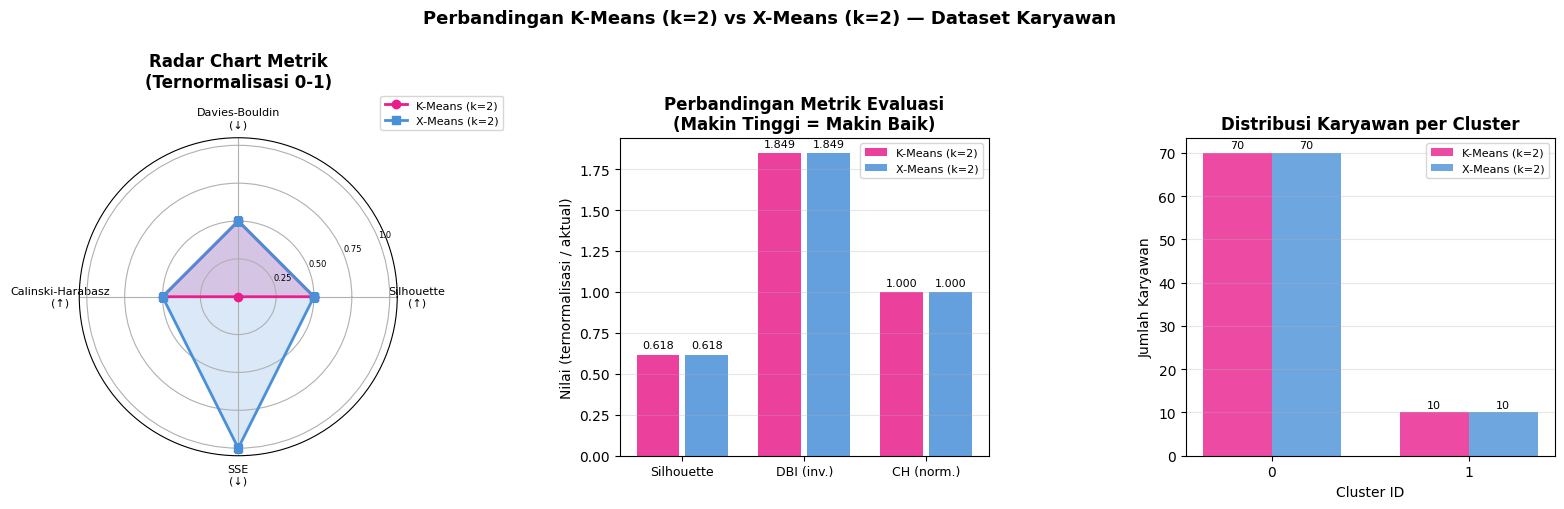

✅ Plot disimpan ke plot_perbandingan_km_xm.png


In [8]:
# ── Radar Chart — Skor Ternormalisasi ─────────────────────────
# Untuk radar, semua metrik dinormalisasi ke 0-1 (makin tinggi = makin baik)
metrics_label = ['Silhouette\n(↑)', 'Davies-Bouldin\n(↓)', 'Calinski-Harabasz\n(↑)', 'SSE\n(↓)']

# Silhouette & CH: tinggi = baik → pakai langsung
# DBI & SSE: rendah = baik → invert dengan 1 - (val/max)
def norm01(a, b, higher_is_better=True):
    if higher_is_better:
        mn, mx = min(a,b), max(a,b)
        if mx == mn: return 0.5, 0.5
        return (a-mn)/(mx-mn), (b-mn)/(mx-mn)
    else:
        mn, mx = min(a,b), max(a,b)
        if mx == mn: return 0.5, 0.5
        return 1-(a-mn)/(mx-mn), 1-(b-mn)/(mx-mn)

km_sil_n, xm_sil_n = norm01(km_sil, xm_sil, True)
km_dbi_n, xm_dbi_n = norm01(km_dbi, xm_dbi, False)
km_ch_n,  xm_ch_n  = norm01(km_ch,  xm_ch,  True)
km_sse_n, xm_sse_n = norm01(km_sse, xm_sse,  False)

km_vals = [km_sil_n, km_dbi_n, km_ch_n, km_sse_n]
xm_vals = [xm_sil_n, xm_dbi_n, xm_ch_n, xm_sse_n]

N = len(metrics_label)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
km_vals += [km_vals[0]]
xm_vals += [xm_vals[0]]
angles  += [angles[0]]

fig = plt.figure(figsize=(16, 5))
fig.suptitle(f'Perbandingan K-Means (k={BEST_K_KM}) vs X-Means (k={BEST_K_XM}) — Dataset Karyawan',
             fontsize=13, fontweight='bold', y=1.01)

# Radar
ax1 = fig.add_subplot(131, polar=True)
ax1.plot(angles, km_vals, 'o-', color='#E91E8C', linewidth=2, label=f'K-Means (k={BEST_K_KM})')
ax1.fill(angles, km_vals, color='#E91E8C', alpha=0.2)
ax1.plot(angles, xm_vals, 's-', color='#4A90D9', linewidth=2, label=f'X-Means (k={BEST_K_XM})')
ax1.fill(angles, xm_vals, color='#4A90D9', alpha=0.2)
ax1.set_xticks(angles[:-1])
ax1.set_xticklabels(metrics_label, fontsize=8)
ax1.set_yticks([0.25, 0.5, 0.75, 1.0])
ax1.set_yticklabels(['0.25','0.50','0.75','1.0'], fontsize=6)
ax1.set_title('Radar Chart Metrik\n(Ternormalisasi 0-1)', fontweight='bold', pad=15)
ax1.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=8)

# Bar Chart Metrik
ax2 = fig.add_subplot(132)
bar_metrics  = ['Silhouette', 'DBI (inv.)', 'CH (norm.)']
km_bar = [km_sil, 1/km_dbi if km_dbi > 0 else 0, km_ch/max(km_ch, xm_ch)]
xm_bar = [xm_sil, 1/xm_dbi if xm_dbi > 0 else 0, xm_ch/max(km_ch, xm_ch)]
x = np.arange(len(bar_metrics))
b1 = ax2.bar(x - 0.2, km_bar, 0.35, label=f'K-Means (k={BEST_K_KM})', color='#E91E8C', alpha=0.85)
b2 = ax2.bar(x + 0.2, xm_bar, 0.35, label=f'X-Means (k={BEST_K_XM})',  color='#4A90D9', alpha=0.85)
ax2.bar_label(b1, fmt='%.3f', padding=3, fontsize=8)
ax2.bar_label(b2, fmt='%.3f', padding=3, fontsize=8)
ax2.set_xticks(x)
ax2.set_xticklabels(bar_metrics, fontsize=9)
ax2.set_title('Perbandingan Metrik Evaluasi\n(Makin Tinggi = Makin Baik)', fontweight='bold')
ax2.legend(fontsize=8)
ax2.grid(axis='y', alpha=0.3)
ax2.set_ylabel('Nilai (ternormalisasi / aktual)')

# Distribusi Cluster
ax3 = fig.add_subplot(133)
km_dist = Counter(km_labels.tolist())
xm_dist = Counter(xm_labels.tolist())
palette = ['#F48FB1','#E91E8C','#4A90D9','#22c55e','#FBBC05','#F15A29','#a78bfa','#22d3ee']
km_counts = [km_dist.get(k, 0) for k in sorted(km_dist)]
xm_counts = [xm_dist.get(k, 0) for k in sorted(xm_dist)]

x_km = np.arange(BEST_K_KM)
x_xm = np.arange(BEST_K_XM)
ax3.bar(x_km, km_counts, color=palette[:BEST_K_KM], alpha=0.85,
        label=f'K-Means (k={BEST_K_KM})', edgecolor='white', linewidth=0.5)
ax3_twin = ax3.twinx() if False else ax3

# Gambar di axes terpisah untuk K-Means vs X-Means
ax3.clear()
bar_width = 0.35
max_k = max(BEST_K_KM, BEST_K_XM)
km_counts_padded = km_counts + [0]*(max_k - len(km_counts))
xm_counts_padded = xm_counts + [0]*(max_k - len(xm_counts))
x_pos = np.arange(max_k)
b1 = ax3.bar(x_pos - bar_width/2, km_counts_padded, bar_width,
             color='#E91E8C', alpha=0.8, label=f'K-Means (k={BEST_K_KM})')
b2 = ax3.bar(x_pos + bar_width/2, xm_counts_padded, bar_width,
             color='#4A90D9', alpha=0.8, label=f'X-Means (k={BEST_K_XM})')
ax3.bar_label(b1, fmt='%d', padding=2, fontsize=8)
ax3.bar_label(b2, fmt='%d', padding=2, fontsize=8)
ax3.set_xlabel('Cluster ID')
ax3.set_ylabel('Jumlah Karyawan')
ax3.set_title('Distribusi Karyawan per Cluster', fontweight='bold')
ax3.legend(fontsize=8)
ax3.grid(axis='y', alpha=0.3)
ax3.set_xticks(x_pos)

plt.tight_layout()
plt.savefig('plot_perbandingan_km_xm.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Plot disimpan ke plot_perbandingan_km_xm.png')

## 8. Visualisasi Scatter — K-Means vs X-Means Side-by-Side

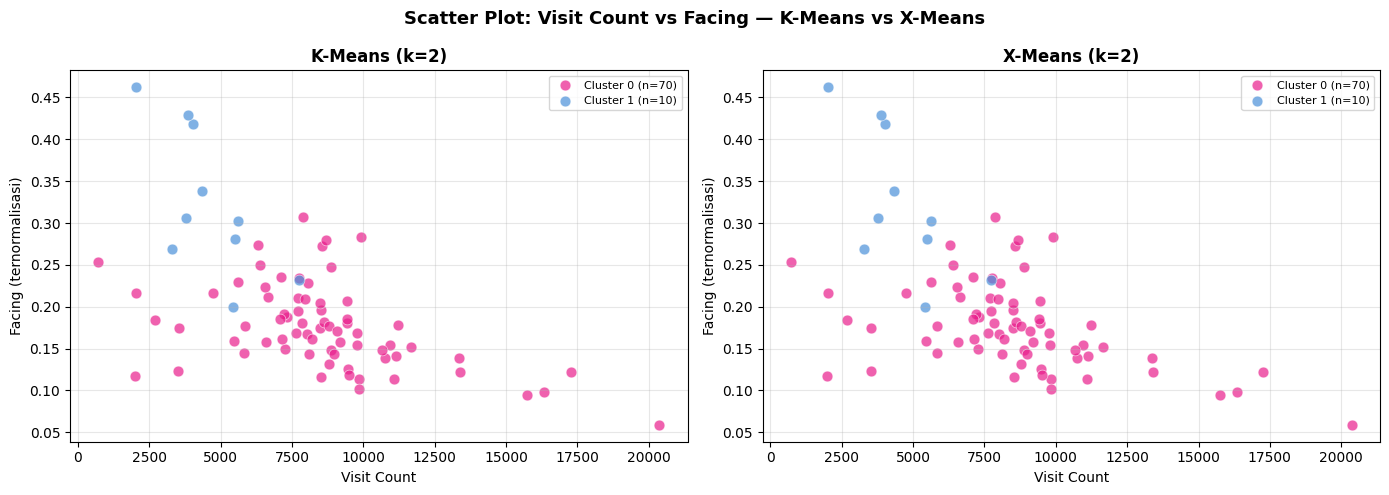

✅ Scatter plot disimpan ke plot_scatter_km_xm.png


In [9]:
palette_ext = ['#E91E8C','#4A90D9','#22c55e','#FBBC05','#F15A29',
               '#a78bfa','#22d3ee','#fbbf24','#fb7185','#4ade80']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Scatter Plot: Visit Count vs Facing — K-Means vs X-Means',
             fontsize=13, fontweight='bold')

for ax, labels_arr, title, best_k in [
    (axes[0], km_labels, f'K-Means (k={BEST_K_KM})', BEST_K_KM),
    (axes[1], xm_labels, f'X-Means (k={BEST_K_XM})',  BEST_K_XM),
]:
    for cid in range(best_k):
        mask = labels_arr == cid
        ax.scatter(
            df_grouped.loc[mask, 'visit_count'],
            df_grouped.loc[mask, 'Facing'],
            c=palette_ext[cid % len(palette_ext)],
            label=f'Cluster {cid} (n={mask.sum()})',
            alpha=0.7, s=60, edgecolors='white', linewidth=0.5
        )
    ax.set_xlabel('Visit Count')
    ax.set_ylabel('Facing (ternormalisasi)')
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('plot_scatter_km_xm.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Scatter plot disimpan ke plot_scatter_km_xm.png')

## 9. Silhouette Plot Side-by-Side

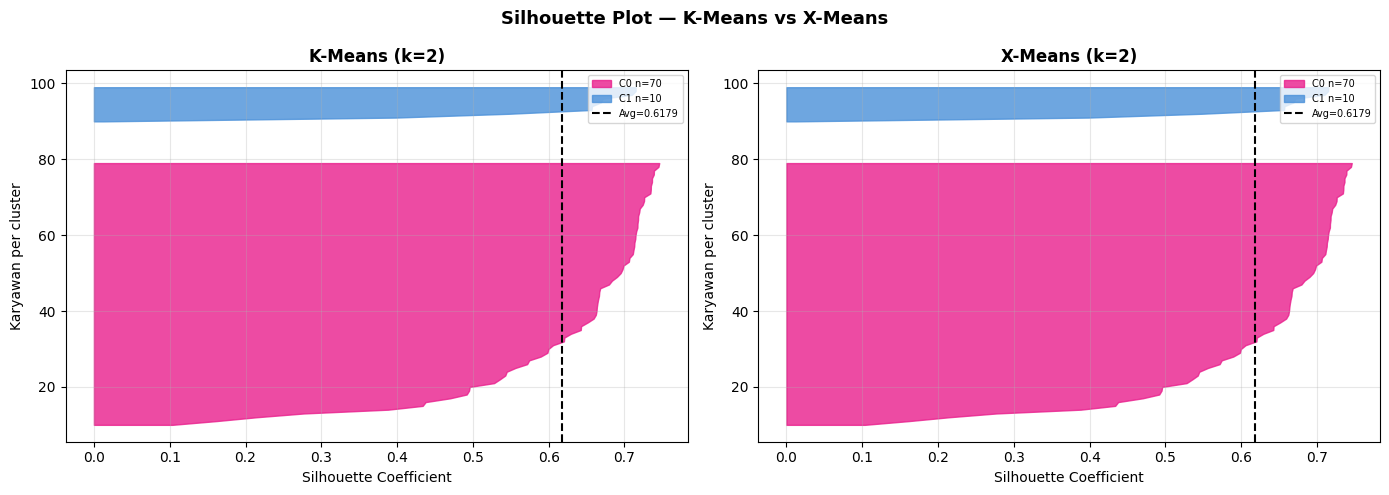

✅ Silhouette plot disimpan ke plot_silhouette_km_xm.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Silhouette Plot — K-Means vs X-Means', fontsize=13, fontweight='bold')

for ax, labels_arr, title, avg_sil, best_k in [
    (axes[0], km_labels, f'K-Means (k={BEST_K_KM})', km_sil, BEST_K_KM),
    (axes[1], xm_labels, f'X-Means (k={BEST_K_XM})',  xm_sil, BEST_K_XM),
]:
    sil_samples = silhouette_samples(X_scaled, labels_arr)
    y_lower = 10
    for cid in range(best_k):
        vals  = np.sort(sil_samples[labels_arr == cid])
        size  = vals.shape[0]
        y_upper = y_lower + size
        color = palette_ext[cid % len(palette_ext)]
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals,
                         facecolor=color, edgecolor=color, alpha=0.8,
                         label=f'C{cid} n={size}')
        y_lower = y_upper + 10
    ax.axvline(x=avg_sil, color='black', linestyle='--', linewidth=1.5,
               label=f'Avg={avg_sil:.4f}')
    ax.set_xlabel('Silhouette Coefficient')
    ax.set_ylabel('Karyawan per cluster')
    ax.set_title(title, fontweight='bold')
    ax.legend(loc='upper right', fontsize=7)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('plot_silhouette_km_xm.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Silhouette plot disimpan ke plot_silhouette_km_xm.png')

## 10. Perbandingan Profil Cluster (Heatmap)

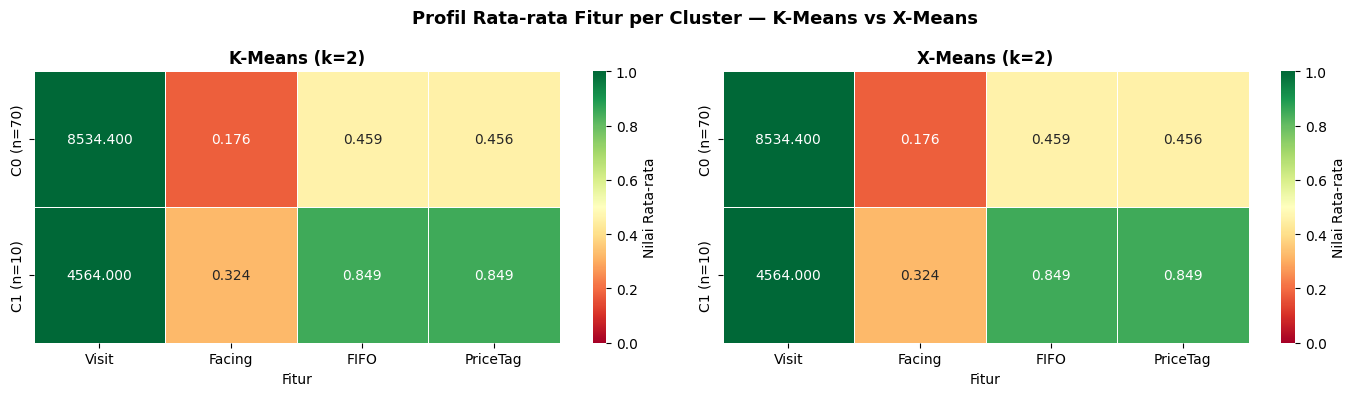

✅ Heatmap profil disimpan ke plot_profil_cluster_km_xm.png


In [11]:
def cluster_profile(labels_arr, best_k):
    rows = []
    for cid in range(best_k):
        mask = labels_arr == cid
        sub  = df_grouped[mask]
        row  = {'Cluster': f'C{cid} (n={mask.sum()})'}
        for col in ACTIVE_FEATURES:
            row[col] = sub[col].mean()
        rows.append(row)
    return pd.DataFrame(rows).set_index('Cluster')

km_profile = cluster_profile(km_labels, BEST_K_KM)
xm_profile = cluster_profile(xm_labels, BEST_K_XM)

fig, axes = plt.subplots(1, 2, figsize=(14, max(4, max(BEST_K_KM, BEST_K_XM) * 0.7)))
fig.suptitle('Profil Rata-rata Fitur per Cluster — K-Means vs X-Means',
             fontsize=13, fontweight='bold')

short_labels = ['Visit' if c == 'visit_count' else
                'Facing' if c == 'Facing' else
                'FIFO' if 'FIFO' in c else 'PriceTag'
                for c in ACTIVE_FEATURES]

for ax, profile, title in [
    (axes[0], km_profile, f'K-Means (k={BEST_K_KM})'),
    (axes[1], xm_profile, f'X-Means (k={BEST_K_XM})'),
]:
    profile_renamed = profile.copy()
    profile_renamed.columns = short_labels
    sns.heatmap(profile_renamed, annot=True, fmt='.3f', cmap='RdYlGn',
                linewidths=0.5, ax=ax, cbar_kws={'label': 'Nilai Rata-rata'},
                vmin=0, vmax=1)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Fitur')
    ax.set_ylabel('')

plt.tight_layout()
plt.savefig('plot_profil_cluster_km_xm.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Heatmap profil disimpan ke plot_profil_cluster_km_xm.png')

## 11. Analisis Balance Distribusi Cluster

Distribusi cluster yang **terlalu tidak seimbang** (satu cluster sangat besar, yang lain sangat kecil) menyulitkan interpretasi HR.  
Kami hitung **Coefficient of Variation (CV)** jumlah anggota — semakin kecil CV, semakin seimbang.

In [12]:
def cluster_balance_stats(labels_arr, best_k, method_name):
    counts = np.array([np.sum(labels_arr == cid) for cid in range(best_k)])
    cv     = counts.std() / counts.mean() * 100  # persen
    ratio  = counts.max() / max(counts.min(), 1)   # rasio terbesar:terkecil
    print(f'{method_name} (k={best_k})')
    print(f'  Distribusi        : {counts.tolist()}')
    print(f'  Rata-rata/cluster : {counts.mean():.1f}')
    print(f'  Std dev           : {counts.std():.1f}')
    print(f'  CV (semakin kecil = semakin seimbang) : {cv:.1f}%')
    print(f'  Rasio terbesar/terkecil               : {ratio:.1f}x')
    return cv, ratio

km_cv, km_ratio = cluster_balance_stats(km_labels, BEST_K_KM, 'K-Means')
print()
xm_cv, xm_ratio = cluster_balance_stats(xm_labels, BEST_K_XM, 'X-Means')
print()
winner = 'K-Means' if km_cv <= xm_cv else 'X-Means'
print(f'Distribusi lebih seimbang : {winner}')

K-Means (k=2)
  Distribusi        : [70, 10]
  Rata-rata/cluster : 40.0
  Std dev           : 30.0
  CV (semakin kecil = semakin seimbang) : 75.0%
  Rasio terbesar/terkecil               : 7.0x

X-Means (k=2)
  Distribusi        : [70, 10]
  Rata-rata/cluster : 40.0
  Std dev           : 30.0
  CV (semakin kecil = semakin seimbang) : 75.0%
  Rasio terbesar/terkecil               : 7.0x

Distribusi lebih seimbang : K-Means


## 12. Ringkasan & Rekomendasi Akhir

In [13]:
# ── Scoring otomatis ──────────────────────────────────────────
criteria = [
    ('Silhouette Score (↑)',    km_sil,   xm_sil,   True),
    ('Davies-Bouldin (↓)',      km_dbi,   xm_dbi,   False),
    ('Calinski-Harabasz (↑)',   km_ch,    xm_ch,    True),
    ('SSE/Inertia (↓)',         km_sse,   xm_sse,   False),
    ('Balance (CV ↓)',          km_cv,    xm_cv,    False),
    ('Waktu Komputasi (↓)',     km_fit_time, xm_fit_time, False),
]

score_km, score_xm = 0, 0
print('=' * 65)
print('         SCORECARD PERBANDINGAN K-Means vs X-Means')
print('=' * 65)
print(f'{"Kriteria":<30} {"K-Means":>12} {"X-Means":>12}  Pemenang')
print('-' * 65)
for name, km_val, xm_val, higher_better in criteria:
    if higher_better:
        win = 'K-Means' if km_val >= xm_val else 'X-Means'
    else:
        win = 'K-Means' if km_val <= xm_val else 'X-Means'
    if win == 'K-Means': score_km += 1
    else: score_xm += 1
    print(f'{name:<30} {km_val:>12.4f} {xm_val:>12.4f}  {win}')

print('-' * 65)
print(f'{"Total skor":<30} {score_km:>12} {score_xm:>12}')
print('=' * 65)

REKOMENDASI = 'K-Means' if score_km >= score_xm else 'X-Means'
alasan_km = [
    f'K otomatis via majority voting (Silhouette, DBI, CH) → lebih robust',
    f'Labeling cluster sudah terintegrasi dengan app.py & dashboard',
    f'Reproducible: random_state=42 menjamin hasil yang konsisten',
    f'Evaluasi mudah dipahami HR (Silhouette, DBI, CH dengan interpretasi jelas)',
]
alasan_xm = [
    f'K ditemukan otomatis tanpa grid search manual',
    f'BIC mencegah overfitting (penalti jumlah parameter)',
    f'Cocok saat K benar-benar tidak diketahui sama sekali',
]

print(f'\n✅ REKOMENDASI : {REKOMENDASI}')
print()
if REKOMENDASI == 'K-Means':
    print('Alasan:')
    for a in alasan_km: print(f'  • {a}')
    print()
    print('Catatan X-Means:')
    for a in alasan_xm: print(f'  • {a}')
    if BEST_K_KM == BEST_K_XM:
        print(f'\n  Keduanya menghasilkan K={BEST_K_KM} — K-Means tetap lebih direkomendasikan')
        print(f'  karena ekosistemnya sudah terintegrasi dengan pipeline skripsi.')
else:
    print('Alasan:')
    for a in alasan_xm: print(f'  • {a}')

print()
print(f'K-Means k={BEST_K_KM}  |  X-Means k={BEST_K_XM}  |  n_karyawan={len(df_grouped)}')
print('=' * 65)

         SCORECARD PERBANDINGAN K-Means vs X-Means
Kriteria                            K-Means      X-Means  Pemenang
-----------------------------------------------------------------
Silhouette Score (↑)                 0.6179       0.6179  K-Means
Davies-Bouldin (↓)                   0.5409       0.5409  K-Means
Calinski-Harabasz (↑)               89.6063      89.6063  K-Means
SSE/Inertia (↓)                      5.2421       5.2421  X-Means
Balance (CV ↓)                      75.0000      75.0000  K-Means
Waktu Komputasi (↓)                  0.0247       0.0024  X-Means
-----------------------------------------------------------------
Total skor                                4            2

✅ REKOMENDASI : K-Means

Alasan:
  • K otomatis via majority voting (Silhouette, DBI, CH) → lebih robust
  • Labeling cluster sudah terintegrasi dengan app.py & dashboard
  • Reproducible: random_state=42 menjamin hasil yang konsisten
  • Evaluasi mudah dipahami HR (Silhouette, DBI, CH dengan in

## 13. Export Tabel Perbandingan ke Excel

In [14]:
# ── Export scorecard ke Excel ─────────────────────────────────
rows_export = []
for name, km_val, xm_val, higher_better in criteria:
    if higher_better:
        win = 'K-Means' if km_val >= xm_val else 'X-Means'
    else:
        win = 'K-Means' if km_val <= xm_val else 'X-Means'
    rows_export.append({'Kriteria': name, 'K-Means': round(km_val, 4),
                        'X-Means': round(xm_val, 4), 'Pemenang': win})

rows_export.append({'Kriteria': 'Total Skor', 'K-Means': score_km,
                    'X-Means': score_xm, 'Pemenang': REKOMENDASI})

df_export = pd.DataFrame(rows_export)
df_export.to_excel('perbandingan_kmeans_xmeans.xlsx', index=False)
print('✅ Tabel perbandingan disimpan ke perbandingan_kmeans_xmeans.xlsx')
df_export

✅ Tabel perbandingan disimpan ke perbandingan_kmeans_xmeans.xlsx


,Kriteria,K-Means,X-Means,Pemenang
0,Silhouette Score (↑),0.6179,0.6179,K-Means
1,Davies-Bouldin (↓),0.5409,0.5409,K-Means
2,Calinski-Harabasz (↑),89.6063,89.6063,K-Means
3,SSE/Inertia (↓),5.2421,5.2421,X-Means
4,Balance (CV ↓),75.0000,75.0000,K-Means
5,Waktu Komputasi (↓),0.0247,0.0024,X-Means
6,Total Skor,4.0000,2.0000,K-Means
